In [93]:
import glob
import open3d as o3d
import cv2
import matplotlib.pyplot as plt
import numpy as np
from Final_Functions import load_and_undistort_images, CalibrateStereoCamera, robot_masking_MOG2
calibration = np.load("calibration_maps.npz")
Q = calibration["Q"]
fps=30


### Disparity maps:

In [94]:
def create_stereo_matchers(min_disparity=0, num_disparities=5*16, block_size=3):
    left_matcher = cv2.StereoSGBM_create(
        minDisparity=min_disparity,
        # Start searching at disparity 0, so far points can still match.
        numDisparities=num_disparities,
        blockSize=block_size,
        P1=8*block_size**2,
        P2=32*block_size**2,
        disp12MaxDiff=1,
        # Drop a pixel when the left-right and right-left disparities differ by more than 1.
        preFilterCap=31,
        # Clip the image gradient so bright spots do not dominate the match cost.
        uniquenessRatio=20,
        # Keep a match only when it beats the second-best cost by xx percent.
        speckleWindowSize=80,
        # Remove connected disparity blobs smaller than 80 pixels.
        speckleRange=2,
        # Pixels in one blob may differ by at most 2 disparity levels.
        mode=cv2.STEREO_SGBM_MODE_SGBM_3WAY,
        # Match along horizontal, vertical, and diagonal paths.
    )
    wls = cv2.ximgproc.createDisparityWLSFilter(left_matcher)
    wls.setLambda(2000)
    wls.setSigmaColor(0.8)
    right_matcher = cv2.ximgproc.createRightMatcher(left_matcher)

    return left_matcher, right_matcher, wls


In [95]:
def calculate_disparity_map(left_matcher, right_matcher, wls, left_image_gray, right_image_gray,test=False):

    disp_left = left_matcher.compute(left_image_gray, right_image_gray)
    disp_right = right_matcher.compute(right_image_gray, left_image_gray)

    # Spread reliable disparity into flat pixels, but stop at a color edge
    disparity_map = wls.filter(disp_left, left_image_gray, None, disp_right).astype(np.float32) / 16
    
    # Invalid pixels are -2048. Keep them out of the color scale.
    disparity_map[disparity_map < 0] = np.nan

    ### TEMP ###
    raw_disparity = disp_left.astype(np.float32) / 16.0
    filtered_disparity = (
        wls.filter(disp_left, left_image_gray, None, disp_right)
        .astype(np.float32) / 16.0
    )
    confidence = wls.getConfidenceMap()
    ### TEMP END ### 
    if test:
        return disparity_map, raw_disparity , confidence
    return disparity_map

In [96]:
def point_cloud_from_disparity(disparity_map, left_image, Q, min_disparity=3, ):   

    points_3D = cv2.reprojectImageTo3D(disparity_map, Q)

    mask = ((disparity_map > min_disparity) & np.isfinite(points_3D).all(axis=2))

    points = points_3D[mask]
    colors = left_image[mask] / 255.0

    pcd = o3d.geometry.PointCloud()

    pcd.points = o3d.utility.Vector3dVector(points)
    pcd.colors = o3d.utility.Vector3dVector(colors)
    
    pcd, ind = pcd.remove_statistical_outlier(nb_neighbors=20, std_ratio=2.0)

    return pcd

In [ ]:
def features_to_3d(features, disparity, Q):
    """Reconstruct 3D feature positions using the stereo Q matrix."""

    xy = features.reshape(-1, 2)

    x = np.rint(xy[:, 0]).astype(int)
    y = np.rint(xy[:, 1]).astype(int)

    h, w = disparity.shape[:2]

    inside = (
        (x >= 0) & (x < w) &
        (y >= 0) & (y < h)
    )

    points_3d = np.full((len(xy), 3), np.nan)

    indices = np.flatnonzero(inside)
    d = disparity[y[indices], x[indices]]

    valid = np.isfinite(d) & (d > 0)

    indices = indices[valid]
    d = d[valid]

    homogeneous = np.column_stack([
        xy[indices, 0],
        xy[indices, 1],
        d,
        np.ones(len(indices)),
    ])

    projected = (Q @ homogeneous.T).T

    with np.errstate(divide="ignore", invalid="ignore"):
        xyz = projected[:, :3] / projected[:, 3:4]

    points_3d[indices] = xyz

    return points_3d

In [98]:
def recover_robot_position(
    left_gray,
    robot_disparity,
    foreground_mask,
    reference_descriptors,
    reference_offsets,
    sift,
    matcher,
    Q,
):
    """Recover the robot origin using previously known features."""

    feature_mask = (
        (foreground_mask > 0).astype(np.uint8) * 255
    )

    # Detect currently visible features
    keypoints, descriptors = sift.detectAndCompute(
        left_gray,
        feature_mask
    )

    if (
        descriptors is None
        or reference_descriptors is None
        or reference_offsets is None
        or len(reference_descriptors) < 2
    ):
        return None, None, None, None

    # Match current features against reference features
    matches = matcher.knnMatch(
        descriptors,
        reference_descriptors,
        k=2
    )

    # Lowe's ratio test
    good_matches = []

    for pair in matches:

        if len(pair) == 2:

            m, n = pair

            if m.distance < 0.75 * n.distance:
                good_matches.append(m)

    # Keep only one match per reference feature
    unique_matches = {}

    for m in sorted(good_matches, key=lambda m: m.distance):

        if m.trainIdx not in unique_matches:
            unique_matches[m.trainIdx] = m

    good_matches = list(unique_matches.values())

    if len(good_matches) < 3:
        return None, None, None, None

    # Get current feature coordinates
    features = np.array(
        [keypoints[m.queryIdx].pt for m in good_matches],
        dtype=np.float32
    ).reshape(-1, 1, 2)

    # Retrieve the original feature offsets
    offsets = np.array([
        reference_offsets[m.trainIdx]
        for m in good_matches
    ])

    # Reconstruct the features in 3D
    features_3d = features_to_3d(
        features,
        robot_disparity,
        Q
    )

    valid = np.isfinite(features_3d).all(axis=1)

    features = features[valid]
    features_3d = features_3d[valid]
    offsets = offsets[valid]

    if len(features_3d) < 3:
        return None, None, None, None

    # Each feature provides an estimate of the origin
    center_estimates = features_3d - offsets

    position = np.median(center_estimates, axis=0)

    return position, features, features_3d, offsets

In [ ]:
def reconstruct_robot_trajectory(
    left_images,
    left_images_gray,
    right_images_gray,
    foreground_masks,
    left_matcher,
    right_matcher,
    wls,
    Q,
    dt,
):
    """Estimate absolute robot positions using 3D feature offsets."""

    robot_pcds = []
    robot_positions = []
    robot_velocities = []

    previous_gray = None
    previous_features = None
    previous_3d = None
    feature_offsets = None
    reference_descriptors = None
    reference_offsets = None

    sift = cv2.SIFT_create(nfeatures=500)
    matcher = cv2.BFMatcher(cv2.NORM_L2)

    initialized = False

    frames = zip(
        left_images,
        left_images_gray,
        right_images_gray,
        foreground_masks,
        strict=True,
    )

    for left_image, left_gray, right_gray, foreground_mask in frames:

        # 1. Calculate disparity and point cloud
        disparity_map = calculate_disparity_map(
            left_matcher, right_matcher, wls,
            left_gray, right_gray
        )

        robot_disparity = disparity_map.copy()
        robot_disparity[foreground_mask <= 0] = np.nan

        robot_pcd = point_cloud_from_disparity(
            robot_disparity, left_image, Q
        )

        robot_pcds.append(robot_pcd)

        position = np.full(3, np.nan)
        velocity = np.full(3, np.nan)

        # 2. Initialize the robot origin and feature offsets
        if not initialized:

            points = np.asarray(robot_pcd.points)
            points = points[np.isfinite(points).all(axis=1)]

            # features = cv2.goodFeaturesToTrack(
            #     left_gray,
            #     maxCorners=250,
            #     qualityLevel=0.01,
            #     minDistance=7,
            #     mask=(foreground_mask > 0).astype(np.uint8) * 255,
            # )

            feature_mask = (
                (foreground_mask > 0).astype(np.uint8) * 255
            )

            keypoints, descriptors = sift.detectAndCompute(
                left_gray,
                feature_mask,
            )

            if len(points) > 0 and descriptors is not None:
                
                # Convert SIFT keypoints to optical flow format
                features = np.array(
                    [kp.pt for kp in keypoints],
                    dtype=np.float32,
                ).reshape(-1, 1, 2)

                features_3d = features_to_3d(
                    features, disparity_map, Q
                )

                valid = np.isfinite(features_3d).all(axis=1)

                features = features[valid]
                features_3d = features_3d[valid]
                descriptors = descriptors[valid]

                if len(features) >= 3:

                    # Fixed robot origin in the initial frame
                    position = points.mean(axis=0)

                    # Store each feature relative to the origin
                    feature_offsets = features_3d - position

                    reference_descriptors = descriptors.copy()
                    reference_offsets = feature_offsets.copy()

                    previous_features = features.copy()
                    previous_3d = features_3d.copy()

                    print("Initialized!")

                    initialized = True

                # Try feature recovery if optical flow failed
        
        # 3. Track existing features
        elif previous_features is not None:

            new_features, status, tracking_error = cv2.calcOpticalFlowPyrLK(
                previous_gray,
                left_gray,
                previous_features,
                None,
                winSize=(21, 21),
                maxLevel=3,
            )

            if new_features is not None and status is not None:

                # Remove features that could not be tracked
                valid = status.ravel() == 1

                new_features = new_features[valid]
                old_3d = previous_3d[valid]
                offsets = feature_offsets[valid]

                print(new_features)

                # 4. Reconstruct new feature positions
                new_3d = features_to_3d(
                    new_features, robot_disparity, Q
                )

                print(new_3d)

                valid_3d = np.isfinite(new_3d).all(axis=1)

                print(valid_3d)

                new_features = new_features[valid_3d]
                new_3d = new_3d[valid_3d]
                old_3d = old_3d[valid_3d]
                offsets = offsets[valid_3d]

                # 5. Calculate absolute robot position
                if len(new_3d) >= 3:

                    center_estimates = new_3d - offsets

                    position = np.median(
                        center_estimates, axis=0
                    )

                    # 6. Calculate velocity from feature motion
                    displacements = new_3d - old_3d

                    velocity = np.median(
                        displacements, axis=0
                    ) / dt

                    # Maintain surviving features and offsets
                    previous_features = new_features
                    previous_3d = new_3d
                    feature_offsets = offsets

                else:
                    previous_features = None
                    previous_3d = None
                    feature_offsets = None

            else:
                previous_features = None
                previous_3d = None
                feature_offsets = None

        if initialized and not np.isfinite(position).all():
        
            recovered_position, features, features_3d, offsets = (
                recover_robot_position(
                    left_gray,
                    robot_disparity,
                    foreground_mask,
                    reference_descriptors,
                    reference_offsets,
                    sift,
                    matcher,
                    Q,
                )
            )

            if recovered_position is not None:

                position = recovered_position

                previous_features = features
                previous_3d = features_3d
                feature_offsets = offsets

                # No consecutive-frame velocity measurement yet
                velocity = np.full(3, np.nan)
        

        robot_positions.append(position)
        robot_velocities.append(velocity)

        previous_gray = left_gray.copy()

    return (
        robot_pcds,
        np.asarray(robot_positions),
        np.asarray(robot_velocities),
    )

In [82]:
# def reconstruct_robot_trajectory(
#     left_images,
#     left_images_gray,
#     right_images_gray,
#     foreground_masks,
#     left_matcher,
#     right_matcher,
#     wls,
#     Q,
#     dt,
# ):
#     """Estimate robot trajectory from tracked 3D features."""

#     robot_pcds = []
#     robot_positions = []
#     robot_velocities = []

#     previous_gray = None
#     previous_disparity = None
#     previous_features = None
#     previous_position = None

#     frames = zip(
#         left_images,
#         left_images_gray,
#         right_images_gray,
#         foreground_masks,
#         strict=True,
#     )

#     for left_image, left_gray, right_gray, foreground_mask in frames:

#         # 1. Calculate disparity map
#         disparity_map = calculate_disparity_map(
#             left_matcher, right_matcher, wls,
#             left_gray, right_gray
#         )

#         # 2. Calculate robot point cloud
#         robot_disparity = disparity_map.copy()
#         robot_disparity[foreground_mask <= 0] = np.nan

#         robot_pcd = point_cloud_from_disparity(
#             robot_disparity, left_image, Q
#         )
#         robot_pcds.append(robot_pcd)

#         # 3. Initialize position from first visible point cloud
#         if previous_position is None:
#             points = np.asarray(robot_pcd.points)

#             if len(points) > 0:
#                 position = points.mean(axis=0)
#             else:
#                 position = np.zeros(3)

#             velocity = np.zeros(3)

#         else:
#             position = previous_position.copy()
#             velocity = np.full(3, np.nan)

#             # 4. Track features using Lucas-Kanade optical flow
#             if previous_features is not None:

#                 new_features, status, _ = cv2.calcOpticalFlowPyrLK(
#                     previous_gray,
#                     left_gray,
#                     previous_features,
#                     None,
#                     winSize=(21, 21),
#                     maxLevel=3,
#                 )

#                 if new_features is not None:

#                     valid = status.ravel() == 1

#                     old_pts = previous_features[valid].reshape(-1, 2)
#                     new_pts = new_features[valid].reshape(-1, 2)

#                     # 5. Keep features inside the robot mask
#                     h, w = foreground_mask.shape[:2]

#                     x = np.rint(new_pts[:, 0]).astype(int)
#                     y = np.rint(new_pts[:, 1]).astype(int)

#                     inside = (
#                         (x >= 0) & (x < w) &
#                         (y >= 0) & (y < h)
#                     )

#                     on_robot = np.zeros(len(new_pts), dtype=bool)

#                     indices = np.flatnonzero(inside)

#                     on_robot[indices] = (
#                         foreground_mask[y[indices], x[indices]] > 0
#                     )

#                     old_pts = old_pts[on_robot]
#                     new_pts = new_pts[on_robot]

#                     # 6. Reconstruct tracked feature positions in 3D
#                     old_3d = features_to_3d(
#                         old_pts, previous_disparity, Q
#                     )

#                     new_3d = features_to_3d(
#                         new_pts, disparity_map, Q
#                     )

#                     valid_3d = (
#                         np.isfinite(old_3d).all(axis=1) &
#                         np.isfinite(new_3d).all(axis=1)
#                     )

#                     old_3d = old_3d[valid_3d]
#                     new_3d = new_3d[valid_3d]

#                     # 7. Estimate robot displacement
#                     if len(old_3d) >= 3:

#                         displacements = new_3d - old_3d

#                         displacement = np.median(
#                             displacements, axis=0
#                         )

#                         velocity = displacement / dt
#                         position = previous_position + displacement

#         robot_positions.append(position)
#         robot_velocities.append(velocity)

#         # 8. Detect features for the next frame
#         feature_mask = (foreground_mask > 0).astype(np.uint8) * 255

#         features = cv2.goodFeaturesToTrack(
#             left_gray,
#             maxCorners=250,
#             qualityLevel=0.01,
#             minDistance=7,
#             mask=feature_mask,
#         )

#         previous_gray = left_gray.copy()
#         previous_disparity = disparity_map.copy()
#         previous_features = features
#         previous_position = position

#     return (
#         robot_pcds,
#         np.asarray(robot_positions),
#         np.asarray(robot_velocities),
#     )

In [83]:
# def reconstruct_robot_trajectory(left_images, left_images_gray, right_images_gray, foreground_masks, left_matcher, right_matcher, wls, Q):
#     """Return robot point clouds and centroid positions for all frames."""

#     robot_pcds = []
#     robot_positions = []

#     frames = zip(left_images, left_images_gray, right_images_gray, foreground_masks, strict=True)

#     for left_image, left_gray, right_gray, foreground_mask in frames:
#         disparity_map = calculate_disparity_map(
#             left_matcher, right_matcher, wls, left_gray, right_gray
#         )

#         # Preserve pixel coordinates while excluding the background.
#         robot_disparity = disparity_map.copy()
#         robot_disparity[foreground_mask <= 0] = np.nan

#         robot_pcd = point_cloud_from_disparity(
#             robot_disparity, left_image, Q
#         )
#         robot_pcds.append(robot_pcd)

#         points = np.asarray(robot_pcd.points)
#         center = (
#             points.mean(axis=0)
#             if len(points) > 0
#             else np.full(3, np.nan)
#         )
#         robot_positions.append(center)

#     return robot_pcds, np.asarray(robot_positions)

In [100]:
def visualize_robot_trajectory(scene_pcd, robot_positions):
    """Show robot centroids and trajectory within the reconstructed scene."""
    positions = np.asarray(robot_positions, dtype=float)
    valid = np.isfinite(positions).all(axis=1)

    if not valid.any():
        raise ValueError("No valid robot positions to visualize.")

    # Map original frame indices to the filtered point indices.
    point_indices = np.full(len(positions), -1, dtype=int)
    point_indices[valid] = np.arange(valid.sum())

    # Connect consecutive frames only, preserving gaps in tracking.
    consecutive = np.flatnonzero(valid[:-1] & valid[1:])
    lines = np.column_stack((
        point_indices[consecutive],
        point_indices[consecutive + 1],
    ))

    trajectory_points = positions[valid]

    centroids = o3d.geometry.PointCloud()
    centroids.points = o3d.utility.Vector3dVector(trajectory_points)
    centroids.paint_uniform_color([1.0, 0.0, 0.0])

    trajectory = o3d.geometry.LineSet()
    trajectory.points = o3d.utility.Vector3dVector(trajectory_points)
    trajectory.lines = o3d.utility.Vector2iVector(lines)
    trajectory.paint_uniform_color([1.0, 0.6, 0.0])

    o3d.visualization.draw_geometries(
        [scene_pcd, centroids, trajectory],
        window_name="Robot trajectory",
        width=1280,
        height=720,
    )

In [101]:
def filter_robot_positions(
    robot_positions,
    dt,
    measurement_std,
    acceleration_std,
    initial_velocity_std,
):
    measurements = np.asarray(robot_positions, dtype=float)
    filtered = np.full_like(measurements, np.nan)

    kf = cv2.KalmanFilter(6, 3, 0, cv2.CV_64F)

    # Position advances according to velocity.
    F = np.eye(6)
    F[:3, 3:] = dt * np.eye(3)
    kf.transitionMatrix = F

    # We measure position, not velocity.
    H = np.zeros((3, 6))
    H[:, :3] = np.eye(3)
    kf.measurementMatrix = H

    # Measurement uncertainty.
    R = measurement_std**2 * np.eye(3)
    kf.measurementNoiseCov = R

    # Model uncertainty: unknown acceleration during each frame interval.
    G = np.vstack([
        0.5 * dt**2 * np.eye(3),
        dt * np.eye(3),
    ])
    kf.processNoiseCov = acceleration_std**2 * (G @ G.T)

    initialized = False

    for i, position in enumerate(measurements):
        valid = np.isfinite(position).all()

        if not initialized:
            if not valid:
                continue

            kf.statePost = np.concatenate([
                position, np.zeros(3)
            ]).reshape(6, 1)

            kf.errorCovPost = np.diag(
                [measurement_std**2] * 3
                + [initial_velocity_std**2] * 3
            )

            filtered[i] = position
            initialized = True
            continue

        prediction = kf.predict()

        if valid:
            estimate = kf.correct(position.reshape(3, 1))
        else:
            estimate = prediction

        filtered[i] = estimate[:3, 0]

    return filtered

In [102]:
def pipeline(left_images,right_images,left_images_gray,right_images_gray,fps):    
### pipeline 
    # Construct stereo matchers
    left_matcher, right_matcher, wls = create_stereo_matchers()

    # Disparity map calculation
    disparity_map = calculate_disparity_map(left_matcher, right_matcher, wls, left_images_gray[0], right_images_gray[0])

    # Construct the scene point cloud from disparity map
    scene_pcd = point_cloud_from_disparity(disparity_map, left_images[0], Q)

    # Construct robot foreground masks.
    robot_foreground_masks = robot_masking_MOG2(left_images)

    # Reconstruct the robot and its trajectory.
    robot_pcds, robot_positions, robot_velocity = reconstruct_robot_trajectory(
        left_images,
        left_images_gray,
        right_images_gray,
        robot_foreground_masks,
        left_matcher,
        right_matcher,
        wls,
        Q,
        1/fps
    )

    filtered_positions = filter_robot_positions(
        robot_positions,
        dt=1 / fps,                         # Actual frame interval in seconds
        measurement_std=0.5,
        acceleration_std=5.0,
        initial_velocity_std=10,
    )

    return scene_pcd, robot_positions, filtered_positions

# Sequence 1

In [103]:
pcd, robot_positions, filtered_positions = pipeline(*load_and_undistort_images("1_no_obstacle"),30)

KeyboardInterrupt: 

In [ ]:
visualize_robot_trajectory(pcd, filtered_positions)

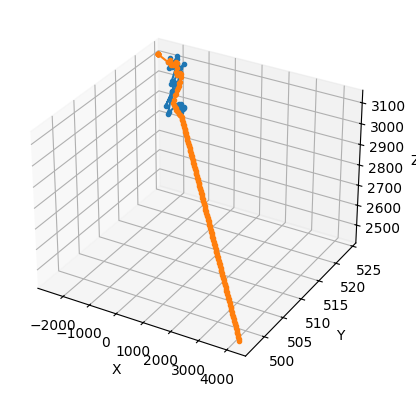

In [ ]:
positions = np.asarray(robot_positions, dtype=float)
filtered_positions = np.asarray(filtered_positions, dtype=float)
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 1], filtered_positions[:, 2], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

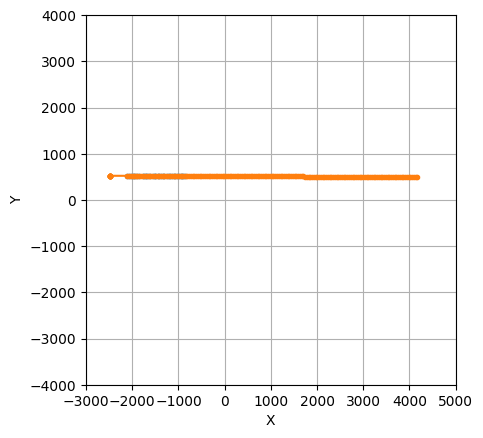

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(positions[:, 0], positions[:, 1], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 1], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
ax.set_xlim([-3000, 5000])
ax.set_ylim([-4000, 4000])
ax.grid(True)
plt.show()

# Sequence 2

In [104]:
pcd, robot_positions, filtered_positions = pipeline(*load_and_undistort_images("2_obstacle"),30)

Initialized!
[[[221.51447   21.168728]]

 [[ 65.135956  -8.03817 ]]

 [[107.88757   21.113932]]

 [[191.20656   24.149834]]

 [[172.02081   29.061386]]

 [[155.12129   30.422205]]]
[[nan nan nan]
 [nan nan nan]
 [nan nan nan]
 [nan nan nan]
 [nan nan nan]
 [nan nan nan]]
[False False False False False False]


In [ ]:
visualize_robot_trajectory(pcd, filtered_positions)

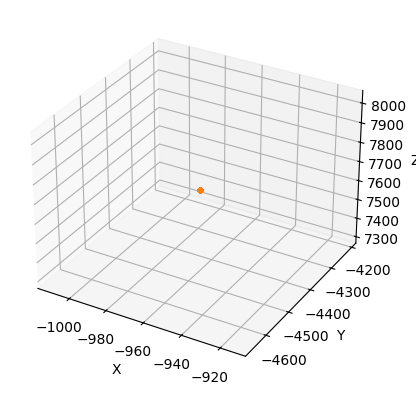

In [ ]:
positions = np.asarray(robot_positions, dtype=float)
filtered_positions = np.asarray(filtered_positions, dtype=float)
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")
ax.plot(positions[:, 0], positions[:, 1], positions[:, 2], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 1], filtered_positions[:, 2], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
plt.show()

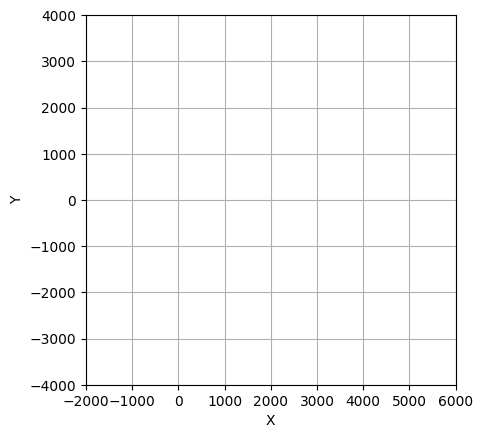

In [ ]:
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(positions[:, 0], positions[:, 1], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 1], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
ax.set_xlim([-2000, 6000])
ax.set_ylim([-4000, 4000])
ax.grid(True)
plt.show()

# 3 Curved Bend

In [ ]:
pcd, robot_positions, filtered_positions = pipeline(*load_and_undistort_images("3_curved_bend"),30)

Initialized!


In [ ]:
visualize_robot_trajectory(pcd, filtered_positions)

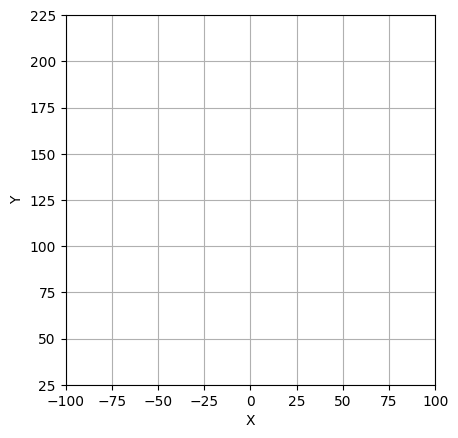

In [ ]:
# %matplotlib widget
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(robot_positions[:, 0], robot_positions[:, 2], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 2], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
ax.set_xlim([-100, 100])
ax.set_ylim([25, 225])
ax.grid(True)
plt.show()

# 4 Circle

In [ ]:
pcd, robot_positions, filtered_positions = pipeline(*load_and_undistort_images("4_circle"),30)

KeyboardInterrupt: 

In [ ]:
visualize_robot_trajectory(pcd, filtered_positions)

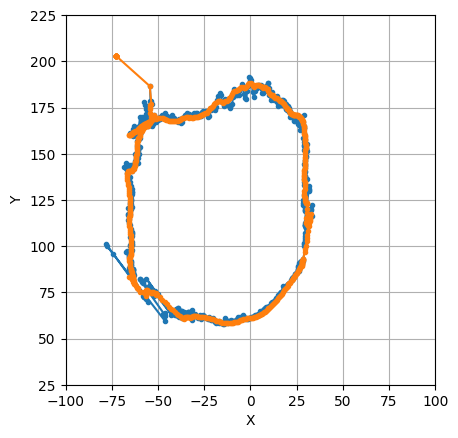

In [ ]:
# %matplotlib widget
fig = plt.figure()
ax = fig.add_subplot(111)
ax.plot(robot_positions[:, 0], robot_positions[:, 2], marker=".")
ax.plot(filtered_positions[:, 0], filtered_positions[:, 2], marker=".")
ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_aspect("equal")
ax.set_xlim([-100, 100])
ax.set_ylim([25, 225])
ax.grid(True)
plt.show()